# Student Performance Analysis

## Project Overview

This project explores student academic performance using Python. The objective is to examine students' mathematics, reading and writing scores and identify patterns across different demographic and educational backgrounds.

The analysis uses Python libraries, including Pandas, Matplotlib and Seaborn, to clean, explore and visualise the dataset.

## Project Objectives
- Examine overall student performance.
- Compare performance across different subjects.
- Investigate differences in performance by gender.
- Explore the relationship between parental education and student scores.
- Examine performance differences based on test preparation status.
- Identify patterns and communicate actionable findings.

## Python Data Analysis Workflow

I imported the necessary Python libraries and loaded the student performance dataset using Pandas.
I inspected the dataset's dimensions, column names, data types, missing values and duplicate records.
I examined the distribution of test preparation records and handled missing entries by labelling them as 'Not Recorded'.
I calculated descriptive statistics, including mean, minimum, maximum and standard deviation.
I created an Overall Score column using the average of Mathematics, Reading and Writing scores.
I calculated average subject scores and identified the highest and lowest overall student performances.
I compared academic performance across gender, parental education and test preparation categories using grouping and aggregation.
I created visualisations to explore subject averages, student demographics and performance distributions.
Finally, I calculated correlations between the three subjects and used a heatmap to visualise their relationships.

In [2]:
import pandas as pd
df = pd.read_excel("student_performance_100.xlsx")
df.head()

,Student ID,Gender,Ethnicity,Parental Education,Test Preparation,Math Score,Reading Score,Writing Score
0,S001,Male,Group A,Bachelor's Degree,Completed,43,68,68
1,S002,Female,Group E,Associate's Degree,Completed,66,75,54
2,S003,Male,Group E,Some College,Completed,58,59,89
3,S004,Male,Group C,Associate's Degree,NaN,49,52,54
4,S005,Female,Group E,High School,NaN,45,54,35


In [3]:
print("Dataset size:", df.shape)

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate records:")
print(df.duplicated().sum())

Dataset size: (100, 8)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   Student ID          100 non-null    str  
 1   Gender              100 non-null    str  
 2   Ethnicity           100 non-null    str  
 3   Parental Education  100 non-null    str  
 4   Test Preparation    41 non-null     str  
 5   Math Score          100 non-null    int64
 6   Reading Score       100 non-null    int64
 7   Writing Score       100 non-null    int64
dtypes: int64(3), str(5)
memory usage: 6.4 KB

Missing values:
Student ID             0
Gender                 0
Ethnicity              0
Parental Education     0
Test Preparation      59
Math Score             0
Reading Score          0
Writing Score          0
dtype: int64

Duplicate records:
0


In [4]:
df["Test Preparation"].value_counts(dropna=False)

Test Preparation
NaN          59
Completed    41
Name: count, dtype: int64

In [5]:
df[["Math Score", "Reading Score", "Writing Score"]].describe()

,Math Score,Reading Score,Writing Score
count,100.000000,100.000000,100.000000
mean,62.510000,60.490000,60.530000
std,13.600724,12.097662,11.468406
min,34.000000,30.000000,32.000000
25%,52.750000,51.000000,53.000000
50%,63.000000,61.000000,60.500000
75%,72.250000,68.250000,68.000000
max,97.000000,90.000000,89.000000


In [6]:
df["Overall Score"] = df[
    ["Math Score", "Reading Score", "Writing Score"]
].mean(axis=1)

print("Overall class average:", df["Overall Score"].mean())

print("\nAverage score per student:")
print(df["Overall Score"].head())

Overall class average: 61.17666666666666

Average score per student:
0    59.666667
1    65.000000
2    68.666667
3    51.666667
4    44.666667
Name: Overall Score, dtype: float64


In [7]:
subject_averages = df[["Math Score", "Reading Score", "Writing Score"]].mean()

print(subject_averages)

Math Score       62.51
Reading Score    60.49
Writing Score    60.53
dtype: float64


In [8]:
print("Highest overall score:", df["Overall Score"].max())

print("Lowest overall score:", df["Overall Score"].min())

print("Students above 70:", (df["Overall Score"] >= 70).sum())

print("Students below 50:", (df["Overall Score"] < 50).sum())

Highest overall score: 78.0
Lowest overall score: 43.666666666666664
Students above 70: 12
Students below 50: 10


In [9]:
gender_performance = df.groupby("Gender")[
    ["Math Score", "Reading Score", "Writing Score", "Overall Score"]
].mean()

print(gender_performance)

        Math Score  Reading Score  Writing Score  Overall Score
Gender                                                         
Female   63.584906      60.830189      59.377358      61.264151
Male     61.297872      60.106383      61.829787      61.078014


In [10]:
parent_education = df.groupby("Parental Education")[
    ["Math Score", "Reading Score", "Writing Score", "Overall Score"]
].mean().round(2)

print(parent_education)

                    Math Score  Reading Score  Writing Score  Overall Score
Parental Education                                                         
Associate's Degree       61.39          60.30          56.83          59.51
Bachelor's Degree        63.06          64.06          62.24          63.12
High School              62.45          60.80          61.75          61.67
Master's Degree          58.46          59.54          59.54          59.18
Some College             70.54          56.77          62.62          63.31
Some High School         60.07          60.36          61.79          60.74


In [11]:
test_prep_performance = df.groupby("Test Preparation")[
    ["Math Score", "Reading Score", "Writing Score", "Overall Score"]
].mean().round(2)

print(test_prep_performance)

                  Math Score  Reading Score  Writing Score  Overall Score
Test Preparation                                                         
Completed              68.34          64.61          66.07          66.34


In [12]:
df["Test Preparation"] = df["Test Preparation"].fillna("Not Recorded")

test_prep_performance = df.groupby("Test Preparation")[
    ["Math Score", "Reading Score", "Writing Score", "Overall Score"]
].mean().round(2)

print(test_prep_performance)

                  Math Score  Reading Score  Writing Score  Overall Score
Test Preparation                                                         
Completed              68.34          64.61          66.07          66.34
Not Recorded           58.46          57.63          56.68          57.59


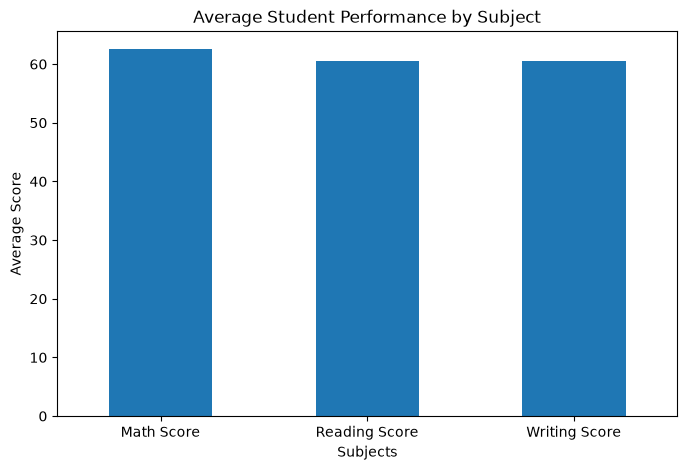

In [15]:
import matplotlib.pyplot as plt

subject_averages = df[
    ["Math Score", "Reading Score", "Writing Score"]
].mean()

plt.figure(figsize=(8, 5))

subject_averages.plot(kind="bar")

plt.title("Average Student Performance by Subject")
plt.xlabel("Subjects")
plt.ylabel("Average Score")
plt.xticks(rotation=0)

plt.show()

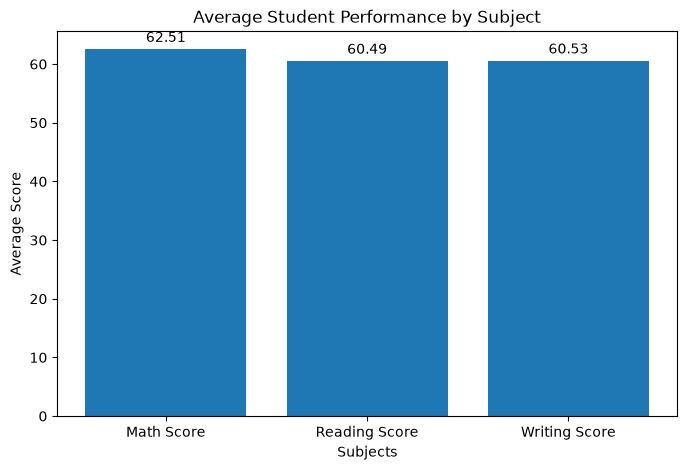

In [16]:
import matplotlib.pyplot as plt

subject_averages = df[
    ["Math Score", "Reading Score", "Writing Score"]
].mean()

plt.figure(figsize=(8, 5))

bars = plt.bar(subject_averages.index, subject_averages.values)

plt.title("Average Student Performance by Subject")
plt.xlabel("Subjects")
plt.ylabel("Average Score")

plt.bar_label(bars, fmt="%.2f", padding=3)

plt.show()

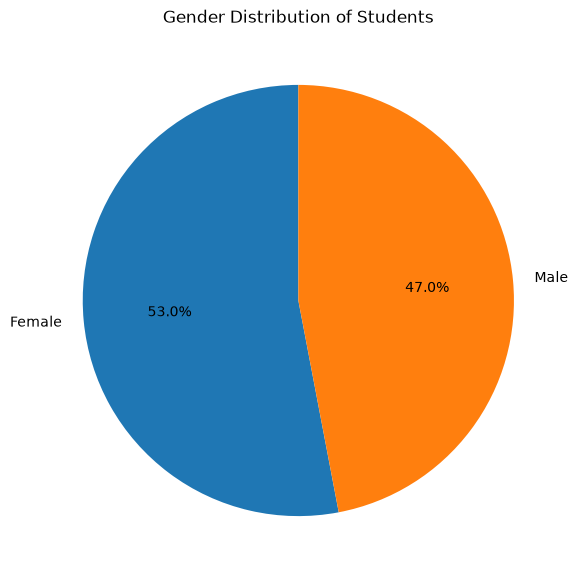

In [17]:
gender_counts = df["Gender"].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    gender_counts,
    labels=gender_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Gender Distribution of Students")

plt.show()

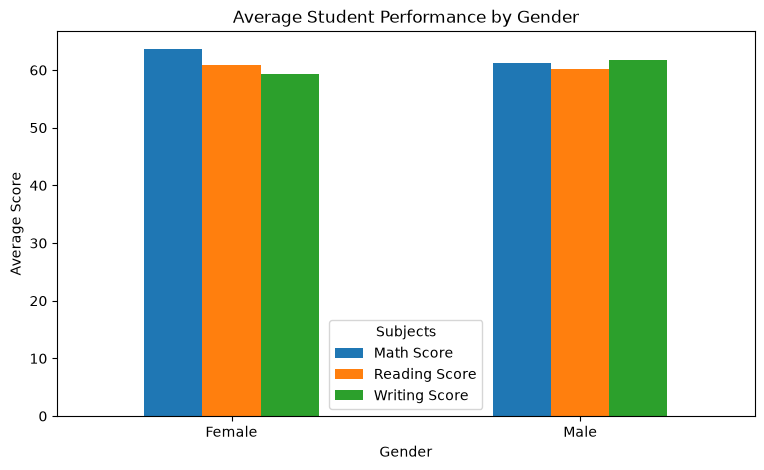

In [18]:
gender_performance[
    ["Math Score", "Reading Score", "Writing Score"]
].plot(kind="bar", figsize=(9, 5))

plt.title("Average Student Performance by Gender")
plt.xlabel("Gender")
plt.ylabel("Average Score")
plt.xticks(rotation=0)
plt.legend(title="Subjects")
plt.show()

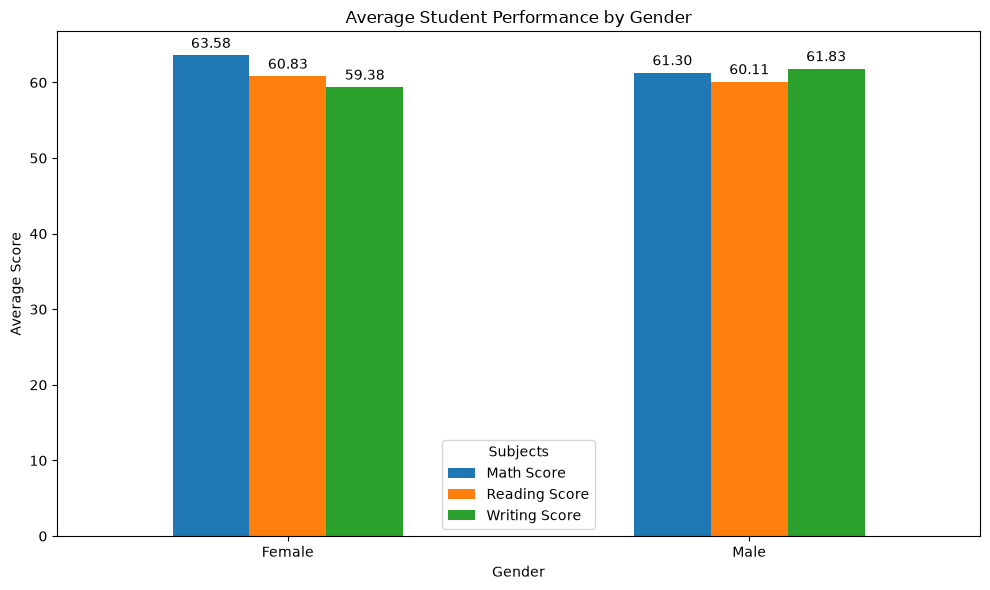

In [19]:
gender_scores = gender_performance[
    ["Math Score", "Reading Score", "Writing Score"]
]

ax = gender_scores.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Average Student Performance by Gender")
plt.xlabel("Gender")
plt.ylabel("Average Score")
plt.xticks(rotation=0)
plt.legend(title="Subjects")

# Add score labels above each bar
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)

plt.tight_layout()
plt.show()

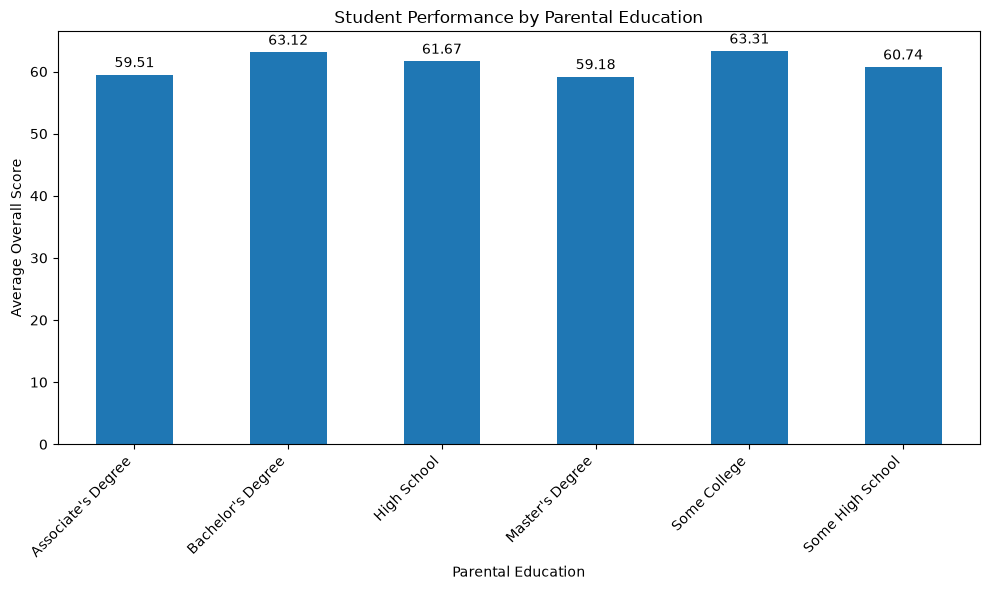

In [20]:
ax = parent_education["Overall Score"].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Student Performance by Parental Education")
plt.xlabel("Parental Education")
plt.ylabel("Average Overall Score")
plt.xticks(rotation=45, ha="right")

ax.bar_label(ax.containers[0], fmt="%.2f", padding=3)

plt.tight_layout()
plt.show()

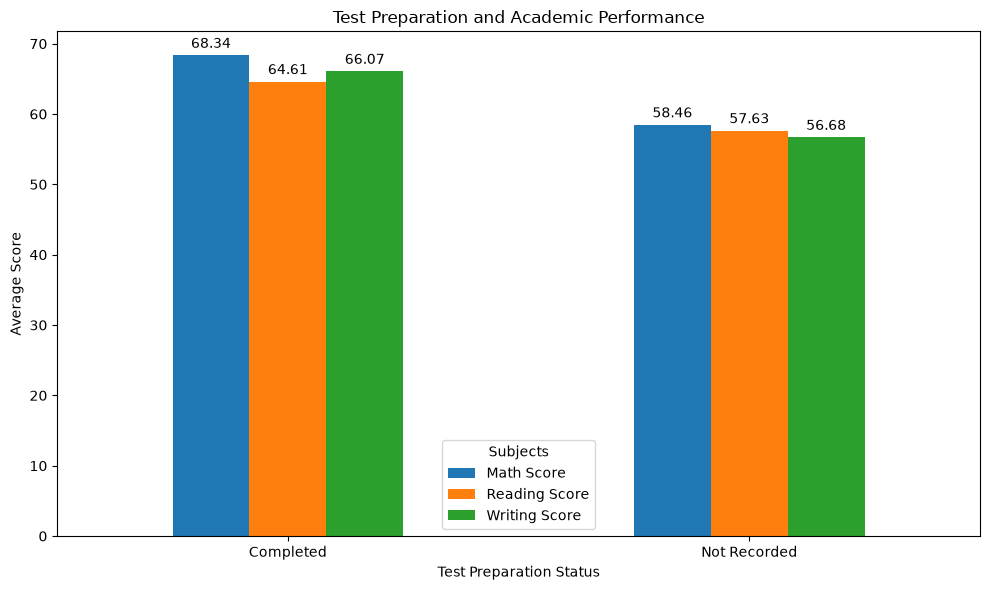

In [21]:
ax = test_prep_performance[
    ["Math Score", "Reading Score", "Writing Score"]
].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Test Preparation and Academic Performance")
plt.xlabel("Test Preparation Status")
plt.ylabel("Average Score")
plt.xticks(rotation=0)
plt.legend(title="Subjects")

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)

plt.tight_layout()
plt.show()

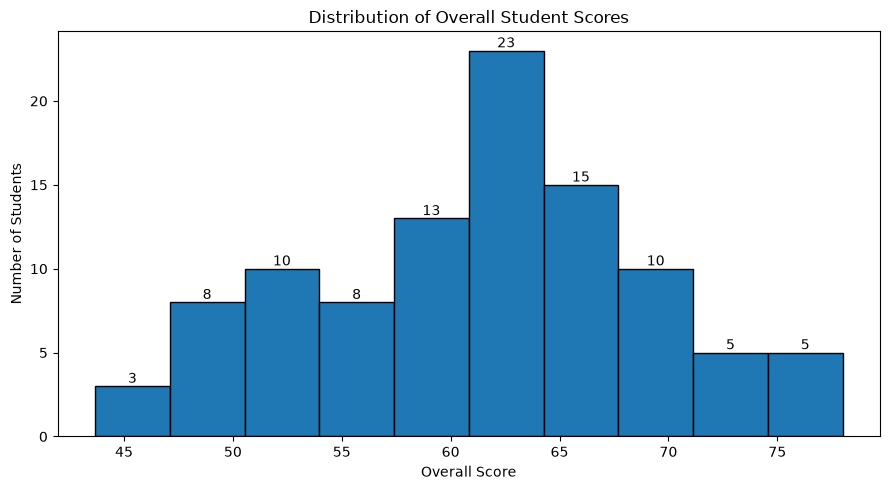

In [23]:
plt.figure(figsize=(9, 5))

counts, bins, patches = plt.hist(
    df["Overall Score"],
    bins=10,
    edgecolor="black"
)

# Add labels above each bar
for count, patch in zip(counts, patches):
    if count > 0:
        plt.text(
            patch.get_x() + patch.get_width() / 2,
            count,
            int(count),
            ha="center",
            va="bottom"
        )

plt.title("Distribution of Overall Student Scores")
plt.xlabel("Overall Score")
plt.ylabel("Number of Students")

plt.tight_layout()
plt.show()

In [24]:
subject_correlation = df[
    ["Math Score", "Reading Score", "Writing Score"]
].corr()

print(subject_correlation.round(2))

               Math Score  Reading Score  Writing Score
Math Score           1.00           0.12           0.09
Reading Score        0.12           1.00           0.07
Writing Score        0.09           0.07           1.00


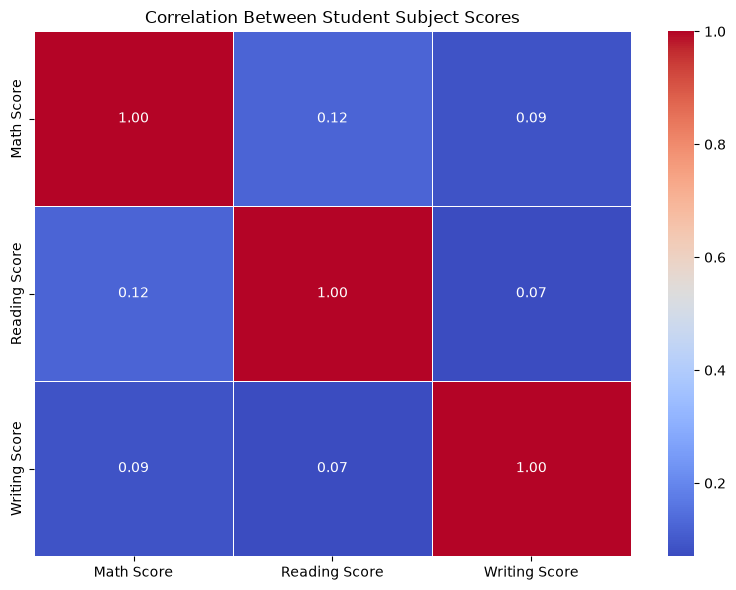

In [26]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

sns.heatmap(
    subject_correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Between Student Subject Scores")

plt.tight_layout()
plt.show()

# Key Findings and Recommendations

## 1. Key Findings

### Subject Performance

Mathematics recorded the highest average score at 62.51, followed by Writing at 60.53 and Reading at 60.49. Although the differences are relatively small, Reading had the lowest average performance. This suggests that students performed at a broadly similar level across the three subjects, with Mathematics showing a slight advantage.

### Overall Student Performance

The overall class average was 61.18. However, looking beyond the average reveals differences in individual performance. While 12 students recorded an overall average of 70 or above, 10 students scored below 50. This indicates that the class average does not fully represent the performance of every student and that some students may require additional academic support.

### Gender and Academic Performance

The gender comparison revealed different patterns across subjects. Female students recorded higher average scores in Mathematics (63.58) and Reading (60.83), while male students performed better in Writing (61.83). Despite these differences, the overall averages were almost identical: 61.26 for female students and 61.08 for male students. This suggests that neither group had a meaningful overall performance advantage in this dataset.

### Parental Education and Student Performance

Students whose parents had some college education recorded the highest overall average of 63.31, closely followed by students whose parents had a bachelor's degree at 63.12. Interestingly, students whose parents had a master's degree recorded the lowest overall average of 59.18.

This shows that the relationship between parental education and student performance is not straightforward. Parental education alone cannot explain academic outcomes, and other factors not captured in this dataset may also influence performance.

### Test Preparation and Academic Performance

Students with a completed test preparation status recorded an average overall score of 66.34, compared with 57.59 among students whose preparation status was not recorded. The difference of 8.75 points is notable and suggests a possible association between test preparation and stronger academic performance.

However, 59 out of the 100 records had no test preparation status. Since these records were classified as "Not Recorded", they cannot automatically be treated as students who did not participate in test preparation. This limits how confidently the difference can be interpreted.

### Relationship Between Subject Scores

The correlation analysis revealed very weak positive relationships between the three subject scores. Mathematics and Reading had a correlation of 0.12, Mathematics and Writing 0.09, while Reading and Writing recorded 0.07.

This suggests that performing well in one subject did not strongly predict performance in another within this sample. Students may therefore have different strengths and weaknesses across subjects.

## 2. Recommendations

1. Prioritise support in Reading: Reading recorded the lowest subject average. Further assessment could help identify the specific areas where students struggle, followed by targeted reading exercises and additional learning support.

2. Use individual performance rather than relying only on class averages: The presence of 10 students scoring below 50 suggests that academic support should be directed towards individual students who are struggling, rather than treating the class as one uniform group.

3. **Evaluate the effectiveness of test preparation: The 8.75-point difference between the two recorded preparation categories is worth investigating further. Schools could encourage structured preparation programmes and maintain complete participation records to determine whether these programmes are associated with improved results.

4. Avoid making assumptions based on gender or parental education: The results show differences between groups, but these differences are relatively small and do not establish that gender or parental education determines academic performance. Support should be based on individual learning needs.

5. Improve the quality of student data collection: Future datasets should include complete test preparation records, attendance, study hours and other relevant learning factors. This would allow a more detailed investigation of what contributes to student performance.

## 3. Limitations of the Analysis

This analysis was conducted using 100 student records and eight original variables. Although the dataset provided information about gender, ethnicity, parental education, test preparation and subject scores, it did not contain attendance records, study hours, class information or examination dates.

Consequently, the analysis could not establish whether attendance, study habits or changes over time influenced academic performance.

Furthermore, 59% of the test preparation records were missing. These were classified as "Not Recorded" to avoid making unsupported assumptions about students' participation.

The findings describe patterns within the available dataset and should not be interpreted as proof of cause-and-effect relationships.
